# ShopSmart - Final Results and Analysis

## 1. Final Model Comparison

This notebook summarizes the validation and test results
of the recommendation algorithms developed for ShopSmart.

We compare recommendation accuracy and catalog coverage.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

PROCESSED_DIR = Path("../data/processed")

# Collaborative Filtering results
cf_test = pd.read_csv(
    PROCESSED_DIR / "collaborative_test_results.csv",
    index_col=0
)

# Content-Based and Popularity results
content_test = pd.read_csv(
    PROCESSED_DIR / "content_popularity_test_results.csv"
)

# Combine the four selected models
cf_test = cf_test.reset_index().rename(
    columns={"index": "Model"}
)

columns = [
    "Model",
    "Precision@10",
    "Hit Rate@10",
    "Coverage"
]

final_results = pd.concat(
    [
        cf_test[columns],
        content_test[columns]
    ],
    ignore_index=True
)

final_results = final_results.sort_values(
    "Hit Rate@10",
    ascending=False
).reset_index(drop=True)

display(final_results)

,Model,Precision@10,Hit Rate@10,Coverage
0,Item-Based KNN,0.0035,0.035,0.3910
1,User-Based KNN V2,0.0027,0.027,0.3885
2,Content-Based TF-IDF,0.0018,0.018,0.5130
3,Popularity Baseline,0.0018,0.018,0.0095


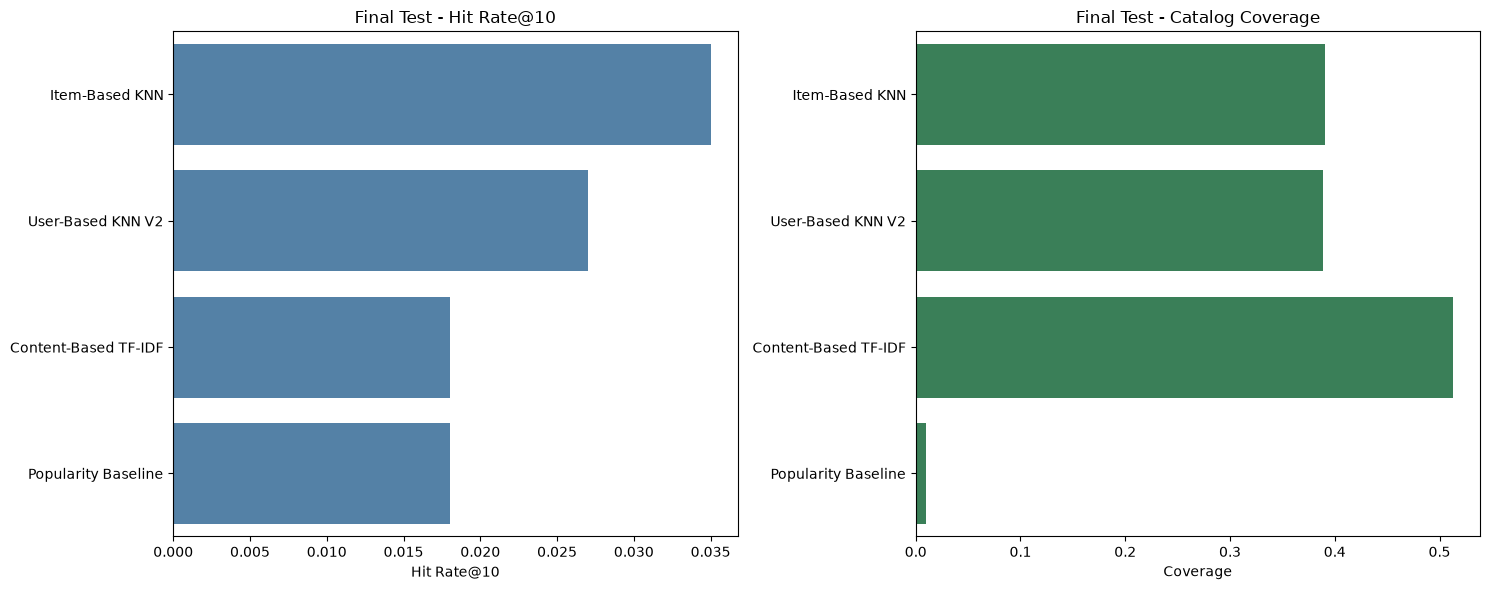

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(
    data=final_results,
    x="Hit Rate@10",
    y="Model",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Final Test - Hit Rate@10")
axes[0].set_xlabel("Hit Rate@10")
axes[0].set_ylabel("")

sns.barplot(
    data=final_results,
    x="Coverage",
    y="Model",
    ax=axes[1],
    color="seagreen"
)

axes[1].set_title("Final Test - Catalog Coverage")
axes[1].set_xlabel("Coverage")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [3]:
final_results.to_csv(
    PROCESSED_DIR / "final_model_results.csv",
    index=False
)

fig.savefig(
    PROCESSED_DIR / "final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

print("Final results and figures saved!")

Final results and figures saved!
